# Notebook 05 — Performance of Model 1: Logistic Regression

**Research topic:** *A Machine Learning Approach to Predicting Retail Investor Dormancy on Digital Investment Platforms*

This notebook evaluates Logistic Regression using classification, discrimination and probability-quality measures. Recall is especially important because false negatives represent dormant investors that the model fails to identify.

In [2]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score,
    matthews_corrcoef, log_loss, brier_score_loss, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)

from sklearn.calibration import calibration_curve
from scipy.stats import chi2_contingency
from statsmodels.stats.contingency_tables import mcnemar

DATA_FILE = Path("outputs/dormancy_modelling_dataset.csv")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42
TEST_SIZE = 0.20
THRESHOLD = 0.50

df = pd.read_csv(DATA_FILE)
X = df.drop(columns=["customer_id", "dormant"])
y = df["dormant"]
categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()
numeric_cols = [c for c in X.columns if c not in categorical_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)


In [3]:

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols)])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        C=1.0, class_weight="balanced", solver="liblinear",
        max_iter=1000, random_state=RANDOM_STATE))
])

model.fit(X_train,y_train)
prob = model.predict_proba(X_test)[:,1]
pred = (prob >= THRESHOLD).astype(int)


In [4]:

def evaluate(y_true, pred, prob):
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0,1]).ravel()
    specificity = tn / (tn + fp) if tn + fp else 0
    return {
        "Accuracy": accuracy_score(y_true,pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true,pred),
        "Precision": precision_score(y_true,pred,zero_division=0),
        "Recall": recall_score(y_true,pred,zero_division=0),
        "Specificity": specificity,
        "F1-score": f1_score(y_true,pred,zero_division=0),
        "ROC-AUC": roc_auc_score(y_true,prob),
        "PR-AUC": average_precision_score(y_true,prob),
        "MCC": matthews_corrcoef(y_true,pred),
        "Log Loss": log_loss(y_true,prob),
        "Brier Score": brier_score_loss(y_true,prob),
        "TP": tp, "TN": tn, "FP": fp, "FN": fn }


In [5]:

results = evaluate(y_test,pred,prob)
display(pd.DataFrame([results]).round(4))
pd.DataFrame([results]).to_csv(
    OUTPUT_DIR/"logistic_regression_performance.csv",index=False)


,Accuracy,Balanced Accuracy,Precision,Recall,Specificity,F1-score,ROC-AUC,PR-AUC,MCC,Log Loss,Brier Score,TP,TN,FP,FN
0,0.6166,0.7358,0.0348,0.859,0.6127,0.0669,0.7866,0.0397,0.1211,0.5248,0.1932,134,5875,3714,22


## Confusion matrix

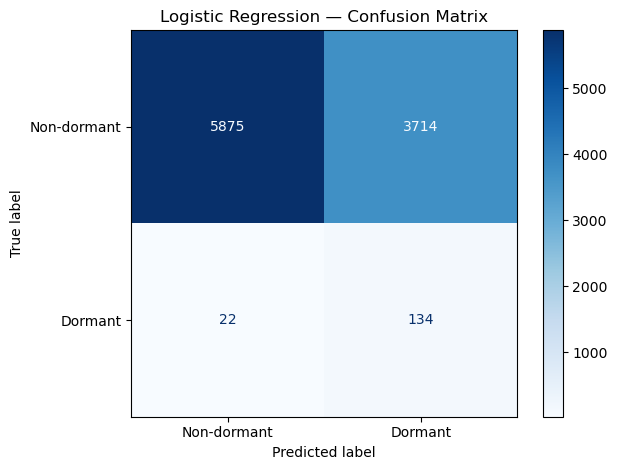

In [6]:

ConfusionMatrixDisplay.from_predictions(
    y_test,pred,display_labels=["Non-dormant","Dormant"],cmap="Blues")

plt.title("Logistic Regression — Confusion Matrix")
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"lr_performance_confusion_matrix.png",dpi=300)
plt.show()


## ROC and Precision-Recall curves

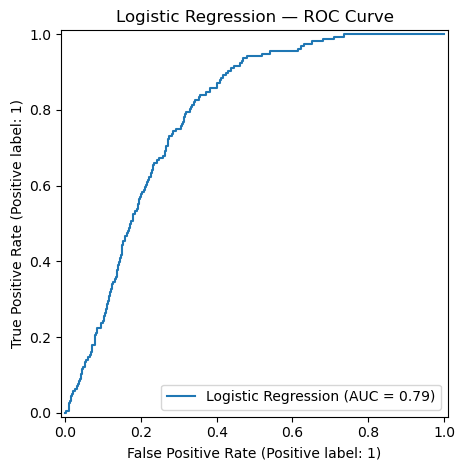

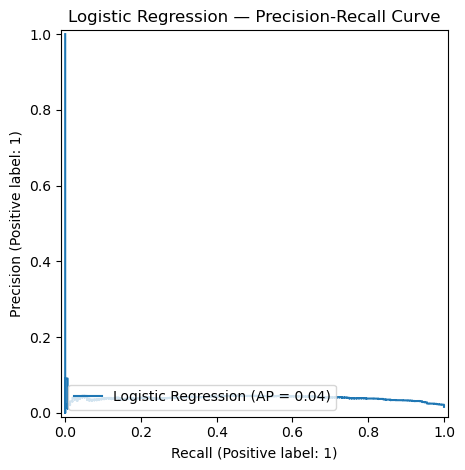

In [7]:

RocCurveDisplay.from_predictions(y_test,prob,name="Logistic Regression")
plt.title("Logistic Regression — ROC Curve")
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"lr_performance_roc_curve.png",dpi=300)
plt.show()

PrecisionRecallDisplay.from_predictions(y_test,prob,name="Logistic Regression")
plt.title("Logistic Regression — Precision-Recall Curve")
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"lr_performance_precision_recall_curve.png",dpi=300)
plt.show()


## Calibration

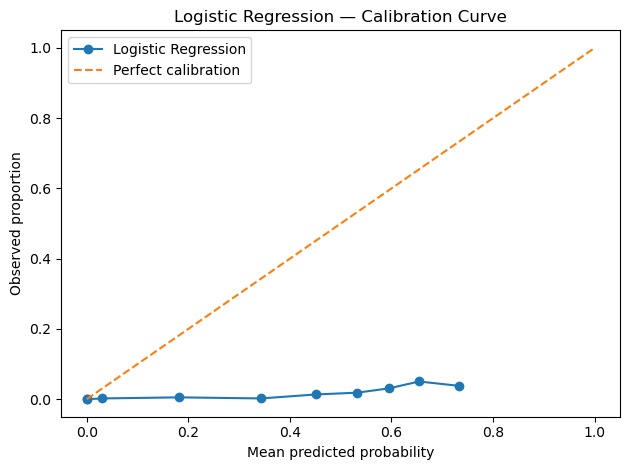

In [8]:

true_prob, predicted_prob = calibration_curve(y_test,prob,n_bins=10,strategy="quantile")

plt.plot(predicted_prob,true_prob,"o-",label="Logistic Regression")
plt.plot([0,1],[0,1],"--",label="Perfect calibration")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed proportion")
plt.title("Logistic Regression — Calibration Curve")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"lr_performance_calibration_curve.png",dpi=300)
plt.show()


## Interpretation and impact

**Recall** measures the proportion of actual dormant investors detected. **Precision** measures how many predicted dormant investors actually become dormant. **F1-score** balances these measures. **ROC-AUC** measures discrimination across thresholds, while **PR-AUC** is useful when dormancy is a minority class. **Specificity** measures the ability to avoid incorrectly flagging non-dormant investors.

For the research problem, false negatives represent investors who become dormant without being identified for possible retention activity. False positives result in unnecessary or poorly targeted interventions. The model's impact therefore needs to be considered alongside the operational cost of these two types of errors.